# Revisiting EWA–EWC Cointegration

## Research Question

Does the historically documented cointegration relationship between the Australian and Canadian equity markets persist in the recent 2022–2026 period?

## Motivation

Australia and Canada share several macroeconomic characteristics, including meaningful exposure to commodities, natural resources, and resource-related industries. This provides an economic rationale for investigating whether their equity markets share a stable long-run relationship.

The EWA–EWC pair was also presented as an example of cointegration in Ernest P. Chan's *Algorithmic Trading*. Rather than assuming that this historical relationship remains stable, this project revisits the pair using recent market data.

The analysis follows a hypothesis-driven approach:

**Economic rationale → Historical evidence → Recent data → Cointegration testing → Statistical conclusion**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import statsmodels.api as sm

from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

## 2. Data Collection

Daily adjusted price data for EWA (iShares MSCI Australia ETF) and EWC (iShares MSCI Canada ETF) are collected using Yahoo Finance via the `yfinance` library.

The sample covers January 2022 through August 2026. Adjusted prices are used to account for distributions and other corporate actions.

In [2]:
tickers =["EWA","EWC"]

start_date = "2022-01-01"
end_date= "2026-08-29"

data=yf.download(tickers, start=start_date, end=end_date,auto_adjust=True, progress=False)

prices =data['Close']

prices.head()

Ticker,EWA,EWC
Date,,
2022-01-03,20.979109,35.317978
2022-01-04,21.299662,34.970013
2022-01-05,21.038158,34.539646
2022-01-06,20.666996,34.805187
2022-01-07,20.768225,35.079899


### Data Validation

Before performing any statistical analysis, the dataset is checked for missing observations and alignment between the two price series.

In [3]:
print(f"Number of observations: {len(prices)}")
print(f"Sample start: {prices.index.min().date()}")
print(f"Sample end: {prices.index.max().date()}")

print("\nMissing values:")
print(prices.isna().sum())

Number of observations: 1168
Sample start: 2022-01-03
Sample end: 2026-08-28

Missing values:
Ticker
EWA    0
EWC    0
dtype: int64


In [4]:
prices.describe()

Ticker,EWA,EWC
count,1168.000000,1168.000000
mean,22.889403,39.884384
std,3.168240,9.024362
min,17.034376,27.993729
25%,20.242486,32.770111
50%,22.448153,36.365005
75%,25.230562,45.390351
max,30.430000,62.639999


## 3. Price Relationship

Before testing for cointegration, the adjusted prices of EWA and EWC are visually inspected over the sample period.

Although the two ETFs may exhibit similar broad movements, visual co-movement alone does not imply cointegration. Formal statistical tests are required to determine whether a stable long-run relationship exists between the two price series.

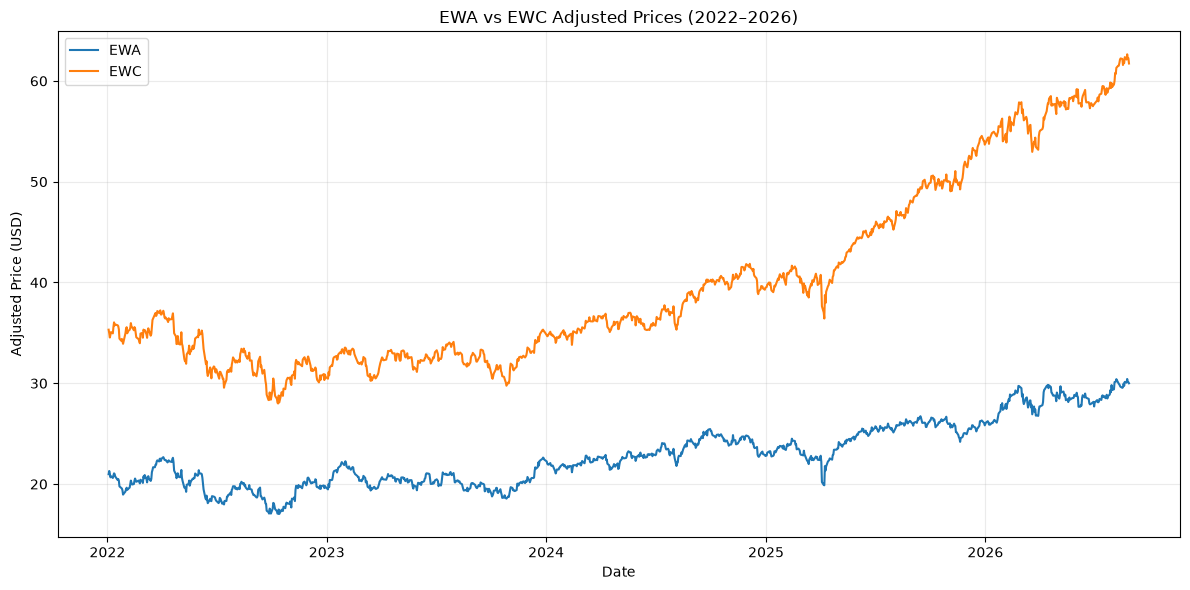

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(prices.index, prices["EWA"], label="EWA")
ax.plot(prices.index, prices["EWC"], label="EWC")

ax.set_title("EWA vs EWC Adjusted Prices (2022–2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Price (USD)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 4. OLS Regression and Hedge Ratio

Following the Engle–Granger framework, the first step is to estimate the long-run relationship between EWC and EWA using Ordinary Least Squares (OLS):

\[
EWC_t = \alpha + \beta EWA_t + \epsilon_t
\]

where:

- \(\alpha\) is the intercept,
- \(\beta\) is the estimated hedge ratio,
- \(\epsilon_t\) is the residual from the estimated relationship.

If the two price series are cointegrated, the residuals from this regression should form a stationary process.

In [6]:
y = prices["EWC"]
x=prices["EWA"]

X = sm.add_constant(x)
model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                    EWC   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                 1.297e+04
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:29:02   Log-Likelihood:                -2769.2
No. Observations:                1168   AIC:                             5542.
Df Residuals:                    1166   BIC:                             5552.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -22.5667      0.554    -40.765      0.0

In [7]:
alpha = results.params["const"]
hedge_ratio = results.params["EWA"]

print(f"Intercept (alpha): {alpha:.4f}")
print(f"Hedge ratio (beta): {hedge_ratio:.4f}")
print(f"R-squared: {results.rsquared:.4f}")

Intercept (alpha): -22.5667
Hedge ratio (beta): 2.7284
R-squared: 0.9175


### OLS Residual Spread

Using the estimated OLS coefficients, the residual spread is constructed as:

\[
\epsilon_t = EWC_t - \alpha - \beta EWA_t
\]

The key question is whether this residual behaves as a stationary process. A stationary residual would provide evidence that the two non-stationary price series share a stable long-run equilibrium relationship.

In [8]:
spread = (
    prices["EWC"]
    - alpha
    - hedge_ratio * prices["EWA"]
)

print("Matches OLS residuals:", np.allclose(spread, results.resid))

Matches OLS residuals: True


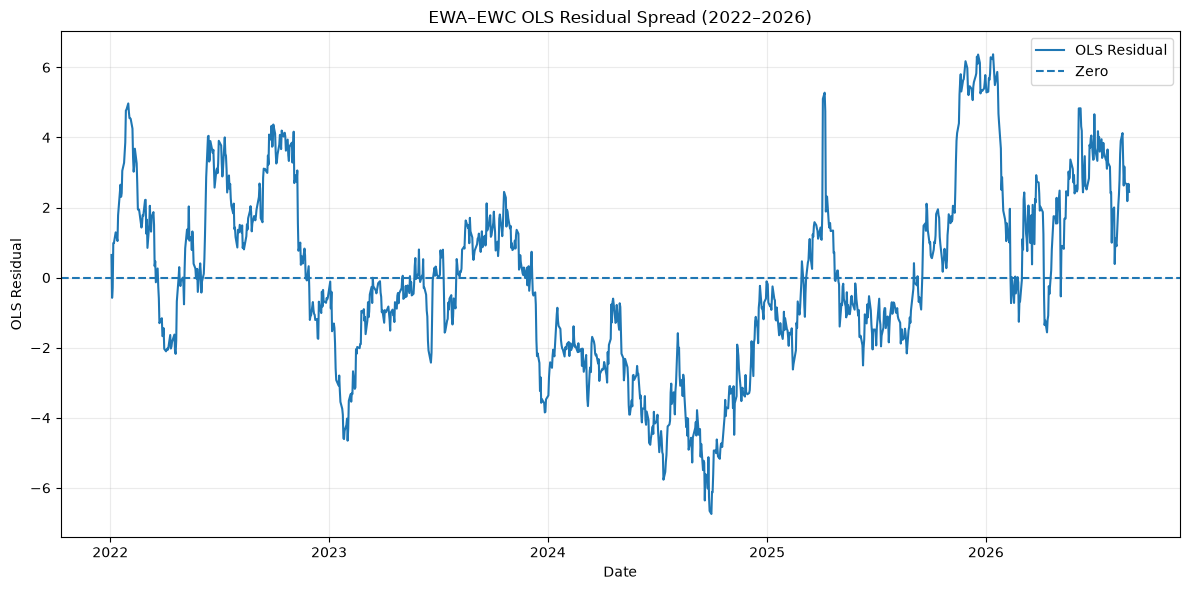

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(spread.index, spread, label="OLS Residual")
ax.axhline(0, linestyle="--", label="Zero")

ax.set_title("EWA–EWC OLS Residual Spread (2022–2026)")
ax.set_xlabel("Date")
ax.set_ylabel("OLS Residual")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Engle–Granger Cointegration Test

Visual inspection of the residual spread is not sufficient to determine whether the relationship is stationary.

The Engle–Granger two-step approach tests whether the residuals from the long-run OLS relationship contain a unit root.

The hypotheses are:

- **H₀:** EWA and EWC are not cointegrated.
- **H₁:** EWA and EWC are cointegrated.

The primary significance level for this analysis is set at **5%**.

In [10]:
coint_stat, p_value, critical_values = coint(
    prices["EWC"],
    prices["EWA"]
)

print(f"Cointegration test statistic: {coint_stat:.4f}")
print(f"p-value: {p_value:.4f}")

print("\nCritical values:")
print(f"1%:  {critical_values[0]:.4f}")
print(f"5%:  {critical_values[1]:.4f}")
print(f"10%: {critical_values[2]:.4f}")

Cointegration test statistic: -2.8961
p-value: 0.1370

Critical values:
1%:  -3.9058
5%:  -3.3414
10%: -3.0481


### Result

For the EWC-on-EWA specification, the cointegration test produces a p-value of approximately **0.137**.

Since:

\[
p = 0.137 > 0.05
\]

the null hypothesis of no cointegration cannot be rejected at the 5% significance level.

The result therefore does not provide sufficient evidence that EWA and EWC are cointegrated under this regression specification.

### Reverse Regression

The Engle–Granger procedure is asymmetric because the first step relies on an OLS regression.

To examine the sensitivity of the result to regression direction, the roles of EWA and EWC are reversed:

\[
EWA_t = \alpha + \beta EWC_t + \epsilon_t
\]

The cointegration test is then repeated using this specification.

In [11]:
reverse_coint_stat, reverse_p_value, reverse_critical_values = coint(
    prices["EWA"],
    prices["EWC"]
)

print(f"Reverse cointegration test statistic: {reverse_coint_stat:.4f}")
print(f"p-value: {reverse_p_value:.4f}")

print("\nCritical values:")
print(f"1%:  {reverse_critical_values[0]:.4f}")
print(f"5%:  {reverse_critical_values[1]:.4f}")
print(f"10%: {reverse_critical_values[2]:.4f}")

Reverse cointegration test statistic: -3.2060
p-value: 0.0689

Critical values:
1%:  -3.9058
5%:  -3.3414
10%: -3.0481


### Reverse Regression Result

Reversing the regression direction produces a stronger cointegration test statistic, with a p-value of approximately **0.069**.

At the pre-specified 5% significance level:

\[
p = 0.069 > 0.05
\]

so the null hypothesis of no cointegration still cannot be rejected.

However, the result would reject the null at the weaker 10% significance level. This sensitivity to regression direction motivates the use of the Johansen test as an additional system-based robustness check.

## 6. Johansen Cointegration Test

As an additional robustness check, the Johansen cointegration test is applied to EWA and EWC.

Unlike the Engle–Granger two-step procedure, which estimates one variable as a function of another, the Johansen approach treats the variables jointly as a system.

For two price series, the relevant cointegration ranks are:

- \(r = 0\): no cointegrating relationship
- \(r = 1\): one cointegrating relationship

The test evaluates the cointegration rank using both the **Trace statistic** and the **Maximum Eigenvalue statistic**.

To remain close to the specification used in the reference analysis, the model is estimated with a constant deterministic term and one lag of differenced variables.

In [12]:
johansen_data = prices[["EWA", "EWC"]]

johansen_result = coint_johansen(
    johansen_data,
    det_order=0,
    k_ar_diff=1
)

c:\Users\Kadir Meriç Kaya\ewa-ewc-cointegration\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
c:\Users\Kadir Meriç Kaya\ewa-ewc-cointegration\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


In [13]:
print("Johansen Trace Test")
print("--------------------")

for i in range(len(johansen_result.lr1)):
    print(
        f"r <= {i}: "
        f"Statistic = {johansen_result.lr1[i]:.4f}, "
        f"90% CV = {johansen_result.cvt[i, 0]:.4f}, "
        f"95% CV = {johansen_result.cvt[i, 1]:.4f}, "
        f"99% CV = {johansen_result.cvt[i, 2]:.4f}"
    )

Johansen Trace Test
--------------------
r <= 0: Statistic = 14.3796, 90% CV = 13.4294, 95% CV = 15.4943, 99% CV = 19.9349
r <= 1: Statistic = 1.6459, 90% CV = 2.7055, 95% CV = 3.8415, 99% CV = 6.6349


In [14]:
print("Johansen Maximum Eigenvalue Test")
print("--------------------------------")

for i in range(len(johansen_result.lr2)):
    print(
        f"r <= {i}: "
        f"Statistic = {johansen_result.lr2[i]:.4f}, "
        f"90% CV = {johansen_result.cvm[i, 0]:.4f}, "
        f"95% CV = {johansen_result.cvm[i, 1]:.4f}, "
        f"99% CV = {johansen_result.cvm[i, 2]:.4f}"
    )

Johansen Maximum Eigenvalue Test
--------------------------------
r <= 0: Statistic = 12.7337, 90% CV = 12.2971, 95% CV = 14.2639, 99% CV = 18.5200
r <= 1: Statistic = 1.6459, 90% CV = 2.7055, 95% CV = 3.8415, 99% CV = 6.6349


### Johansen Test Results

At the pre-specified 5% significance level, neither the Trace test nor the Maximum Eigenvalue test rejects the null hypothesis of zero cointegrating relationships.

However, both statistics exceed their respective 10% critical values for \(r=0\).

Therefore, the Johansen test does not provide sufficient evidence of cointegration at the conventional 5% level, although it provides weaker evidence of one cointegrating relationship at the 10% level.

This result is broadly consistent with the reverse Engle–Granger test, which also produced marginal evidence of cointegration at the 10% level.

## 7. Results Summary

The table below summarizes the cointegration tests applied to EWA and EWC over the 2022–2026 sample.

The primary decision threshold was set at the 5% significance level before interpreting the test results.

In [15]:
results_summary = pd.DataFrame({
    "Test": [
        "Engle–Granger: EWC ~ EWA",
        "Engle–Granger: EWA ~ EWC",
        "Johansen Trace: r = 0",
        "Johansen Max-Eigen: r = 0"
    ],
    "Statistic": [
        coint_stat,
        reverse_coint_stat,
        johansen_result.lr1[0],
        johansen_result.lr2[0]
    ],
    "5% Critical Value": [
        critical_values[1],
        reverse_critical_values[1],
        johansen_result.cvt[0, 1],
        johansen_result.cvm[0, 1]
    ],
    "5% Result": [
        "Fail to reject",
        "Fail to reject",
        "Fail to reject",
        "Fail to reject"
    ]
})

results_summary

,Test,Statistic,5% Critical Value,5% Result
0,Engle–Granger: EWC ~ EWA,-2.896098,-3.341371,Fail to reject
1,Engle–Granger: EWA ~ EWC,-3.205980,-3.341371,Fail to reject
2,Johansen Trace: r = 0,14.379638,15.494300,Fail to reject
3,Johansen Max-Eigen: r = 0,12.733691,14.263900,Fail to reject


At the 5% significance level, none of the tests provide sufficient evidence to reject the null hypothesis of no cointegration.

The results are not entirely devoid of evidence, however. The reverse Engle–Granger specification has a p-value of approximately 0.069, while both Johansen statistics exceed their respective 10% critical values for the null of zero cointegrating relationships.

Therefore, the recent sample provides weaker evidence of cointegration at the 10% level, but this evidence is not strong enough to satisfy the pre-specified 5% criterion.

## 8. Conclusion

This project revisited the historical EWA–EWC cointegration relationship using daily adjusted prices from 2022 to 2026.

The pair was motivated by both economic intuition and prior empirical evidence. Australia and Canada have meaningful exposure to commodities and natural-resource-related industries, while the EWA–EWC pair has previously been documented as an example of cointegration.

The recent data, however, provide weaker evidence of a stable long-run relationship.

The Engle–Granger test using EWC as the dependent variable fails to reject the null hypothesis of no cointegration. Reversing the regression direction produces stronger evidence, but the result remains insignificant at the pre-specified 5% level.

The Johansen Trace and Maximum Eigenvalue tests lead to a similar conclusion. Neither rejects zero cointegrating relationships at the 5% level, although both reject at the weaker 10% level.

Overall, the analysis does not provide sufficient evidence at the 5% significance level that the historical EWA–EWC cointegration relationship persisted during the 2022–2026 sample.

For this reason, the analysis stops at the statistical validation stage rather than proceeding directly to the construction and backtesting of a mean-reversion trading strategy.

## 9. Limitations and Further Research

Several limitations should be considered when interpreting these results:

- **Sample dependence:** The analysis focuses only on the 2022–2026 period. Cointegration relationships may change across different market regimes.

- **Structural instability:** The tests assume a relatively stable long-run relationship over the selected sample. Potential structural breaks or time-varying hedge ratios are not explicitly modeled.

- **Model specification:** The Johansen test uses a deterministic specification and lag structure chosen to remain close to the reference analysis. A more extensive study could select lag length and deterministic components using formal model-selection procedures.

- **Pair selection:** The economic relationship between Australia and Canada provides a rationale for examining EWA and EWC, but economic similarity does not guarantee statistical cointegration.

- **No trading backtest:** Transaction costs, short-selling constraints, execution, position sizing, and trading performance are not analyzed because the pair did not satisfy the pre-specified 5% cointegration criterion.

Further research could investigate whether the relationship is regime-dependent by applying rolling or expanding-window cointegration tests, structural-break methods, or time-varying parameter models.